## 1. 데이터 로딩 및 구로구 추출

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_KEY = "어린이집기본정보_서울_UTF8"

def find_repo():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if p.name == "do_not_lung" and (p / "notebooks").is_dir():
            return p
        candidate = p / "do_not_lung"
        if (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("do_not_lung 저장소 없음")

REPO = find_repo()
DATA_ROOT = REPO.parent / "data"
RAW_ROOT = DATA_ROOT / "raw_data"
OUT_DIR = DATA_ROOT / "processed_data" / DATASET_KEY

candidates = sorted(
    RAW_ROOT.rglob("어린이집기본정보_서울_UTF8*.csv"),
    key=lambda p: (
        p.name != "어린이집기본정보_서울_UTF8.csv",
        str(p)
    )
)
if not candidates:
    raise FileNotFoundError(f"원본 CSV가 없습니다: {RAW_ROOT}")

RAW_PATH = candidates[0]

for encoding in ["utf-8-sig", "cp949", "euc-kr"]:
    try:
        raw = pd.read_csv(
            RAW_PATH, encoding=encoding, dtype="string"
        )
        break
    except UnicodeDecodeError:
        continue
else:
    raise UnicodeError("CSV 인코딩 확인 실패")

required = [
    "시도", "시군구", "어린이집명", "어린이집유형구분",
    "운영현황", "주소", "정원수", "현원수", "위도", "경도"
]
missing_cols = set(required) - set(raw.columns)
if missing_cols:
    raise ValueError(f"필수 컬럼 누락: {missing_cols}")

mask = (
    raw["시도"].str.strip().eq("서울특별시")
    & raw["시군구"].str.strip().eq("구로구")
)

selected = raw.loc[mask].copy()
if selected.empty:
    raise ValueError("구로구 어린이집이 발견되지 않았습니다.")

selected.insert(0, "source_row_id", selected.index + 1)
selected.reset_index(drop=True, inplace=True)

print("원본:", RAW_PATH.name)
print("인코딩:", encoding)
print("pandas:", pd.__version__)
print("전체:", raw.shape)
print("구로구:", selected.shape)
print("메모리(MB):", round(
    selected.memory_usage(deep=True).sum() / 1024**2, 3
))
display(selected.head())
display(selected.dtypes.to_frame("dtype"))
display(selected.nunique(dropna=True).to_frame("unique_count"))

원본: 어린이집기본정보_서울_UTF8.csv
인코딩: utf-8-sig
pandas: 3.0.6
전체: (4078, 23)
구로구: (222, 24)
메모리(MB): 0.311


,source_row_id,시도,시군구,어린이집명,어린이집유형구분,운영현황,우편번호,주소,어린이집전화번호,어린이집팩스번호,...,보육교직원수,정원수,현원수,위도,경도,통학차량운영여부,홈페이지주소,인가일자,휴지시작일자,휴지종료일자
0,2421,서울특별시,구로구,명화어린이집,국공립,정상,08337,서울특별시 구로구 개봉로17다길 6 (개봉동),02-2612-2552,02-2612-3793,...,17,79,65,37.49344959,126.8551028,미운영,<NA>,1999-02-01,<NA>,<NA>
1,2422,서울특별시,구로구,꿈이있는어린이집,국공립,정상,08281,서울특별시 구로구 벚꽃로 484 화원사회종합복지관내 (구로동),02-863-0106,02-863-0170,...,15,74,59,37.4973289,126.8801416,미운영,http://kids.guro.kr,2005-09-01,<NA>,<NA>
2,2423,서울특별시,구로구,이편한어린이집,민간,정상,08211,서울특별시 구로구 신도림로 16 대림아파트 관리동1층 (신도림동),02-6741-5629,02-6741-5629,...,13,69,53,37.50551204420249,126.8791520519068,미운영,https://www.instagram.com/ekidlove,2005-01-12,<NA>,<NA>
3,2424,서울특별시,구로구,별나라어린이집,가정,정상,08205,"서울특별시 구로구 신도림로11가길 36 5동 101호(신도림동, 미성아파트)",02-2068-9993,02-2068-9993,...,7,19,16,37.50827362315886,126.87610798295601,미운영,<NA>,2005-11-15,<NA>,<NA>
4,2425,서울특별시,구로구,미래어린이집,국공립,정상,08314,서울특별시 구로구 구로동로20길 57 (구로동),02-853-1474,02-853-1470,...,9,67,39,37.48804867,126.8876312,미운영,http://mirea.0363.net,1989-04-19,<NA>,<NA>


,dtype
source_row_id,int64
시도,string
시군구,string
어린이집명,string
어린이집유형구분,string
운영현황,string
우편번호,string
주소,string
어린이집전화번호,string
어린이집팩스번호,string


,unique_count
source_row_id,222
시도,1
시군구,1
어린이집명,222
어린이집유형구분,7
운영현황,3
우편번호,121
주소,222
어린이집전화번호,222
어린이집팩스번호,184


## 2. 전처리 및 품질 플래그

In [2]:
clean = selected.copy()

for c in clean.select_dtypes(include=["string"]).columns:
    clean[c] = clean[c].str.strip().replace("", pd.NA)

numeric_cols = [
    "보육실수", "보육실면적", "놀이터수", "CCTV설치수",
    "보육교직원수", "정원수", "현원수", "위도", "경도"
]

for c in numeric_cols:
    if c in clean.columns:
        clean[c] = pd.to_numeric(clean[c], errors="coerce")

date_cols = ["인가일자", "휴지시작일자", "휴지종료일자"]
for c in date_cols:
    if c in clean.columns:
        clean[c] = pd.to_datetime(
            clean[c], errors="coerce"
        ).dt.strftime("%Y-%m-%d")

clean["coord_valid_broad"] = (
    clean["위도"].between(33, 39)
    & clean["경도"].between(124, 132)
).fillna(False)

clean["address_guro_match"] = (
    clean["주소"].str.contains("구로구", na=False)
)

clean["duplicate_coordinate_flag"] = (
    clean.duplicated(["위도", "경도"], keep=False)
    & clean[["위도", "경도"]].notna().all(axis=1)
)

clean["duplicate_name_flag"] = (
    clean["어린이집명"].duplicated(keep=False)
    & clean["어린이집명"].notna()
)

clean["over_capacity_flag"] = (
    clean["현원수"] > clean["정원수"]
).fillna(False)

clean["invalid_capacity_flag"] = (
    clean["정원수"].isna()
    | clean["현원수"].isna()
    | clean["정원수"].lt(0)
    | clean["현원수"].lt(0)
)

clean["occupancy_rate_pct"] = np.where(
    clean["정원수"] > 0,
    100 * clean["현원수"] / clean["정원수"],
    np.nan
)

clean["review_needed"] = (
    ~clean["coord_valid_broad"]
    | ~clean["address_guro_match"]
    | clean["duplicate_coordinate_flag"]
    | clean["duplicate_name_flag"]
    | clean["over_capacity_flag"]
    | clean["invalid_capacity_flag"]
    | clean["인가일자"].isna()
)

print("전처리 전:", selected.shape)
print("전처리 후:", clean.shape)
print("완전 중복:", int(selected.duplicated().sum()))
print("좌표 중복 행:", int(
    clean["duplicate_coordinate_flag"].sum()
))
print("이름 중복 행:", int(
    clean["duplicate_name_flag"].sum()
))
print("정원 초과 시설:", int(
    clean["over_capacity_flag"].sum()
))
print("검토 필요 행:", int(clean["review_needed"].sum()))

display(clean.loc[clean["review_needed"]].head(30))

전처리 전: (222, 24)
전처리 후: (222, 32)
완전 중복: 0
좌표 중복 행: 32
이름 중복 행: 0
정원 초과 시설: 0
검토 필요 행: 32


,source_row_id,시도,시군구,어린이집명,어린이집유형구분,운영현황,우편번호,주소,어린이집전화번호,어린이집팩스번호,...,휴지시작일자,휴지종료일자,coord_valid_broad,address_guro_match,duplicate_coordinate_flag,duplicate_name_flag,over_capacity_flag,invalid_capacity_flag,occupancy_rate_pct,review_needed
11,2432,서울특별시,구로구,폴디어린이집,가정,정상,08211,"서울특별시 구로구 신도림로 16 103동 101호(신도림동, 대림2차아파트)",02-2636-3512,02-2636-3512,...,NaN,NaN,True,True,True,False,False,False,100.000000,True
12,2433,서울특별시,구로구,고척어린이집,국공립,정상,08224,서울특별시 구로구 중앙로5길 62 (고척동),02-2686-9745,02-2686-9743,...,NaN,NaN,True,True,True,False,False,False,73.809524,True
15,2436,서울특별시,구로구,꽃사슴어린이집,가정,정상,08329,"서울특별시 구로구 개봉로20길 6 102동 103호(개봉동, 현대아파트)",02-2066-8959,02-6737-1402,...,NaN,NaN,True,True,True,False,False,False,100.000000,True
23,2444,서울특별시,구로구,장미어린이집,민간,정상,08226,서울특별시 구로구 경인로 343 삼환로즈빌아파트 단지 내 1층 장미 어린이집 (고척동),02-2060-0406,02-2060-0406,...,NaN,NaN,True,True,True,False,False,False,100.000000,True
28,2449,서울특별시,구로구,대림어린이집,가정,정상,08211,"서울특별시 구로구 신도림로 16 501동 102호(신도림동, 대림1차아파트)",02-2635-7147,--,...,NaN,NaN,True,True,True,False,False,False,100.000000,True
29,2450,서울특별시,구로구,아기둥지어린이집,가정,정상,08275,"서울특별시 구로구 경인로 390 210동 103호(고척동, 벽산블루밍)",02-2616-2356,02-2616-2234,...,NaN,NaN,True,True,True,False,False,False,90.000000,True
37,2458,서울특별시,구로구,새연어린이집,민간,정상,08294,서울특별시 구로구 구로중앙로28다길 15 (구로동),02-852-7171,02-857-9772,...,NaN,NaN,True,True,True,False,False,False,69.387755,True
65,2486,서울특별시,구로구,이현어린이집,가정,정상,08275,"서울특별시 구로구 경인로 382 101동 102호(개봉동, 한마을아파트)",02-2613-2720,02-2613-2720,...,NaN,NaN,True,True,True,False,False,False,55.000000,True
66,2487,서울특별시,구로구,로뎀어린이집,가정,정상,08291,"서울특별시 구로구 새말로 31 107동 102호(구로동, 롯데아파트)",02-851-6199,02-851-6199,...,NaN,NaN,True,True,True,False,False,False,100.000000,True
72,2493,서울특별시,구로구,한마을어린이집,민간,정상,08275,서울특별시 구로구 경인로 382 한마을아파트상가 (관리동2층) (개봉동),02-2689-5123,02-2689-5141,...,NaN,NaN,True,True,True,False,False,False,43.750000,True


## 3. 결측치 및 기초 통계

In [3]:
missing = pd.DataFrame({
    "missing_count": selected.isna().sum(),
    "missing_pct": selected.isna().mean() * 100
})
display(missing)

type_counts = clean["어린이집유형구분"].value_counts()
status_counts = clean["운영현황"].value_counts()

print("\n어린이집 유형")
display(type_counts.to_frame("count"))

print("\n운영 상태")
display(status_counts.to_frame("count"))

capacity_total = clean["정원수"].sum()
enrollment_total = clean["현원수"].sum()

print("정원 합계:", capacity_total)
print("현원 합계:", enrollment_total)

if capacity_total > 0:
    print(
        "전체 정원 대비 현원 비율(%):",
        round(100 * enrollment_total / capacity_total, 2)
    )

display(clean[numeric_cols].describe())

print("인가지정 날짜 범위:")
print("최초:", clean["인가일자"].min())
print("최근:", clean["인가일자"].max())

,missing_count,missing_pct
source_row_id,0,0.000000
시도,0,0.000000
시군구,0,0.000000
어린이집명,0,0.000000
어린이집유형구분,0,0.000000
운영현황,0,0.000000
우편번호,0,0.000000
주소,0,0.000000
어린이집전화번호,0,0.000000
어린이집팩스번호,0,0.000000



어린이집 유형


,count
어린이집유형구분,
국공립,94
가정,64
민간,49
직장,7
법인·단체등,3
사회복지법인,3
협동,2



운영 상태


,count
운영현황,
정상,215
재개,4
휴지,3


정원 합계: 10280
현원 합계: 7188
전체 정원 대비 현원 비율(%): 69.92


,보육실수,보육실면적,놀이터수,CCTV설치수,보육교직원수,정원수,현원수,위도,경도
count,222.0,222.0,222.0,222.0,222.0,222.0,222.0,222.0,222.0
mean,4.522523,187.121622,0.783784,9.301802,10.761261,46.306306,32.378378,37.494727,126.86286
std,1.851241,185.704891,1.01487,7.941181,5.487273,32.888896,23.632194,0.009016,0.02231
min,2.0,33.0,0.0,0.0,0.0,13.0,0.0,37.474612,126.815712
25%,3.0,67.25,0.0,4.0,7.0,20.0,17.0,37.488307,126.845692
50%,4.0,128.0,0.0,6.5,9.0,33.5,21.5,37.494457,126.861119
75%,5.0,250.0,1.0,12.0,13.75,69.0,46.75,37.501861,126.883891
max,11.0,1649.0,5.0,83.0,41.0,168.0,118.0,37.513763,126.898341


인가지정 날짜 범위:
최초: 1961-05-05
최근: 2024-02-22


## 4. 시각화

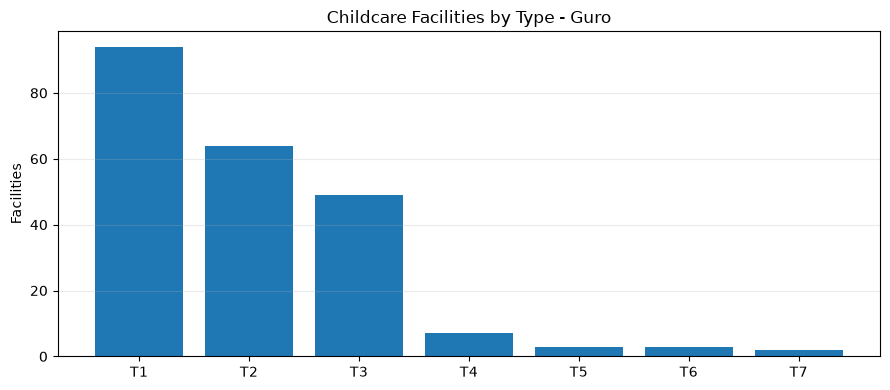

T1: 국공립
T2: 가정
T3: 민간
T4: 직장
T5: 법인·단체등
T6: 사회복지법인
T7: 협동


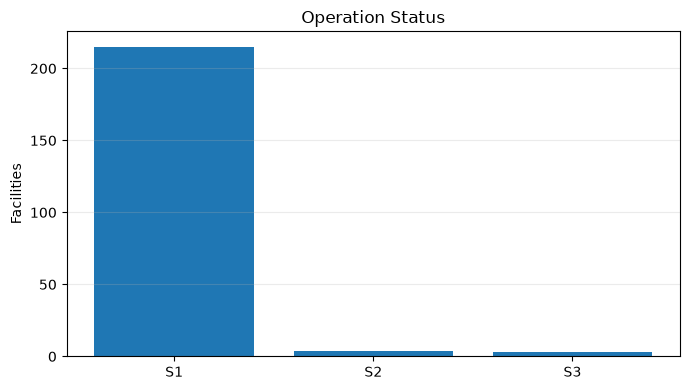

S1: 정상
S2: 재개
S3: 휴지


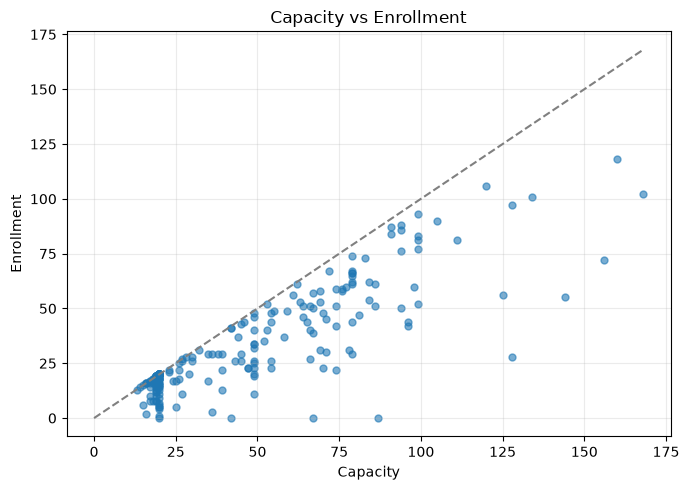

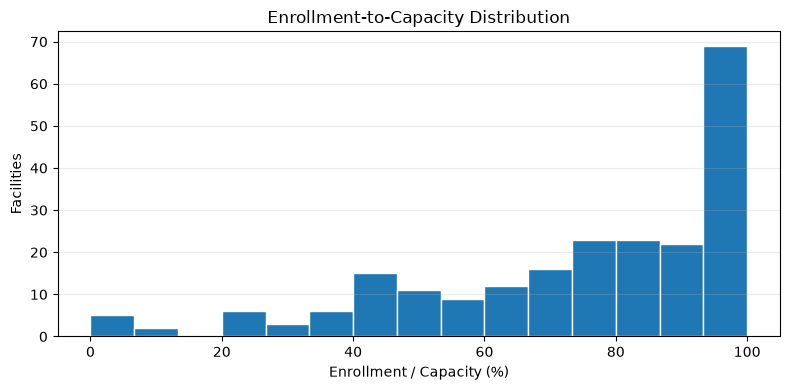

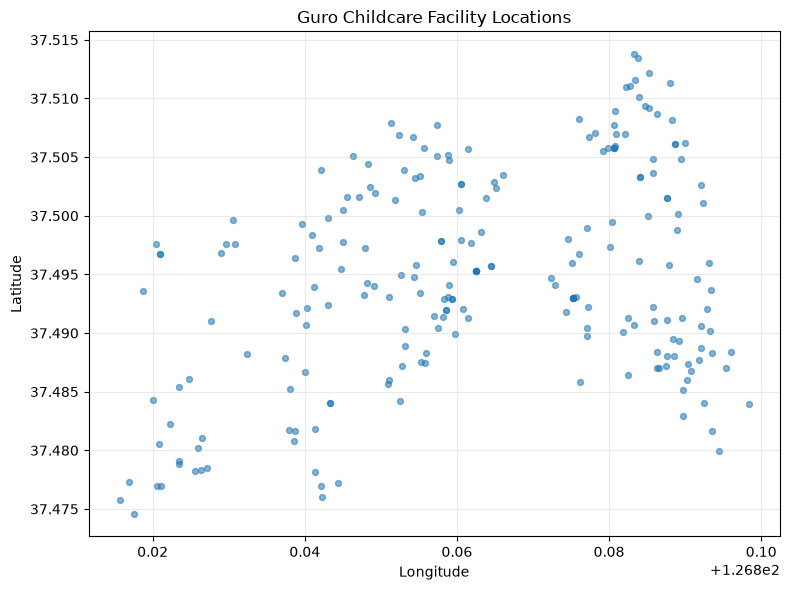

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(type_counts))
ax.bar(x, type_counts.values)
ax.set_xticks(x)
ax.set_xticklabels([f"T{i+1}" for i in x])
ax.set_title("Childcare Facilities by Type - Guro")
ax.set_ylabel("Facilities")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

for i, name in enumerate(type_counts.index, 1):
    print(f"T{i}: {name}")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(status_counts))
ax.bar(x, status_counts.values)
ax.set_xticks(x)
ax.set_xticklabels([f"S{i+1}" for i in x])
ax.set_title("Operation Status")
ax.set_ylabel("Facilities")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

for i, name in enumerate(status_counts.index, 1):
    print(f"S{i}: {name}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    clean["정원수"], clean["현원수"],
    alpha=0.6, s=25
)
max_value = max(
    clean["정원수"].max(), clean["현원수"].max()
)
ax.plot(
    [0, max_value], [0, max_value],
    linestyle="--", color="gray"
)
ax.set_xlabel("Capacity")
ax.set_ylabel("Enrollment")
ax.set_title("Capacity vs Enrollment")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    clean["occupancy_rate_pct"].dropna(),
    bins=15, edgecolor="white"
)
ax.set_xlabel("Enrollment / Capacity (%)")
ax.set_ylabel("Facilities")
ax.set_title("Enrollment-to-Capacity Distribution")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
valid = clean["coord_valid_broad"]
ax.scatter(
    clean.loc[valid, "경도"],
    clean.loc[valid, "위도"],
    alpha=0.55, s=18
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Guro Childcare Facility Locations")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. summary 및 features 생성

In [5]:
rows = []

def add(section, metric, category, value, unit=""):
    rows.append({
        "section": section,
        "metric": metric,
        "category": category,
        "value": value,
        "unit": unit
    })

overall = {
    "seoul_rows": len(raw),
    "guro_rows": len(clean),
    "original_columns": len(raw.columns),
    "exact_duplicates": int(selected.duplicated().sum()),
    "unique_names": clean["어린이집명"].nunique(),
    "unique_coordinates": len(
        clean[["위도", "경도"]].drop_duplicates()
    ),
    "duplicate_coordinate_rows": int(
        clean["duplicate_coordinate_flag"].sum()
    ),
    "duplicate_name_rows": int(
        clean["duplicate_name_flag"].sum()
    ),
    "invalid_coordinate_rows": int(
        (~clean["coord_valid_broad"]).sum()
    ),
    "address_mismatch_rows": int(
        (~clean["address_guro_match"]).sum()
    ),
    "over_capacity_rows": int(
        clean["over_capacity_flag"].sum()
    ),
    "review_needed_rows": int(clean["review_needed"].sum()),
    "capacity_total": capacity_total,
    "enrollment_total": enrollment_total
}

for metric, value in overall.items():
    add("overall", metric, "", value, "count")

if capacity_total > 0:
    add(
        "overall", "overall_occupancy_pct", "",
        100 * enrollment_total / capacity_total, "%"
    )

for category, count in type_counts.items():
    add("facility_type", "count", category, count, "facilities")

for category, count in status_counts.items():
    add("operation_status", "count", category, count, "facilities")

for col in selected.columns:
    add(
        "missing", "count", col,
        selected[col].isna().sum(), "rows"
    )
    add(
        "missing", "percent", col,
        selected[col].isna().mean() * 100, "%"
    )

for col in ["정원수", "현원수", "보육교직원수",
            "보육실수", "보육실면적", "위도", "경도"]:
    if col in clean:
        for stat in ["min", "max", "mean", "median", "std"]:
            add(
                "numeric", stat, col,
                getattr(clean[col], stat)()
            )

summary = pd.DataFrame(rows)

feature_cols = [
    "source_row_id", "위도", "경도",
    "정원수", "현원수", "보육교직원수",
    "보육실수", "보육실면적", "놀이터수",
    "occupancy_rate_pct", "coord_valid_broad",
    "duplicate_coordinate_flag", "review_needed",
    "어린이집유형구분", "운영현황"
]

features = clean[feature_cols].rename(columns={
    "위도": "latitude",
    "경도": "longitude",
    "정원수": "capacity",
    "현원수": "enrollment",
    "보육교직원수": "staff_count",
    "보육실수": "classroom_count",
    "보육실면적": "classroom_area",
    "놀이터수": "playground_count",
    "어린이집유형구분": "facility_type",
    "운영현황": "operation_status"
})

features = pd.get_dummies(
    features,
    columns=["facility_type", "operation_status"],
    dtype=int
)

print("clean:", clean.shape)
print("summary:", summary.shape)
print("features:", features.shape)
display(features.head())

clean: (222, 32)
summary: (108, 5)
features: (222, 23)


,source_row_id,latitude,longitude,capacity,enrollment,staff_count,classroom_count,classroom_area,playground_count,occupancy_rate_pct,...,facility_type_가정,facility_type_국공립,facility_type_민간,facility_type_법인·단체등,facility_type_사회복지법인,facility_type_직장,facility_type_협동,operation_status_재개,operation_status_정상,operation_status_휴지
0,2421,37.49345,126.855103,79,65,17,5,314,3,82.278481,...,0,1,0,0,0,0,0,0,1,0
1,2422,37.497329,126.880142,74,59,15,5,250,1,79.729730,...,0,1,0,0,0,0,0,0,1,0
2,2423,37.505512,126.879152,69,53,13,4,304,1,76.811594,...,0,0,1,0,0,0,0,0,1,0
3,2424,37.508274,126.876108,19,16,7,3,55,0,84.210526,...,1,0,0,0,0,0,0,0,1,0
4,2425,37.488049,126.887631,67,39,9,5,173,1,58.208955,...,0,1,0,0,0,0,0,0,1,0


## 6. CSV 저장 및 검증

In [6]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

outputs = {
    "clean.csv": clean,
    "summary.csv": summary,
    "features.csv": features
}

loaded = {}

for name, frame in outputs.items():
    path = OUT_DIR / name
    frame.to_csv(
        path, index=False, encoding="utf-8-sig"
    )

    dtype_map = (
        {
            "우편번호": "string",
            "어린이집전화번호": "string",
            "어린이집팩스번호": "string"
        }
        if name == "clean.csv" else None
    )

    saved = pd.read_csv(
        path,
        encoding="utf-8-sig",
        dtype=dtype_map
    )

    assert saved.shape == frame.shape, name
    assert list(saved.columns) == list(frame.columns), name
    assert path.read_bytes().startswith(b"\xef\xbb\xbf")

    loaded[name] = saved

for name in ["clean.csv", "features.csv"]:
    assert (
        loaded[name]["source_row_id"].tolist()
        == outputs[name]["source_row_id"].tolist()
    )

for c in ["위도", "경도"]:
    assert np.allclose(
        loaded["clean.csv"][c].to_numpy(dtype=float),
        clean[c].to_numpy(dtype=float),
        equal_nan=True,
        atol=1e-9,
        rtol=0
    )

print("CSV 저장 및 검증 완료")

CSV 저장 및 검증 완료


## 7. README.md 자동 생성

In [7]:
descriptions = {
    "source_row_id": "서울 원본 행 순서 기반 식별자",
    "시도": "시도명",
    "시군구": "시군구명",
    "어린이집명": "어린이집 이름",
    "어린이집유형구분": "어린이집 운영 유형",
    "운영현황": "원본 운영 상태",
    "우편번호": "우편번호",
    "주소": "어린이집 소재지 주소",
    "어린이집전화번호": "어린이집 전화번호",
    "어린이집팩스번호": "어린이집 팩스번호",
    "보육실수": "보육실 개수",
    "보육실면적": "보육실 면적(원본 단위 확인 필요)",
    "놀이터수": "놀이터 개수",
    "CCTV설치수": "CCTV 설치 수",
    "보육교직원수": "보육교직원 수",
    "정원수": "어린이집 정원",
    "현원수": "어린이집 현원",
    "위도": "위도 좌표",
    "경도": "경도 좌표",
    "통학차량운영여부": "통학차량 운영 정보",
    "홈페이지주소": "어린이집 홈페이지 주소",
    "인가일자": "어린이집 인가일자",
    "휴지시작일자": "휴지 시작일자",
    "휴지종료일자": "휴지 종료일자",
    "coord_valid_broad": "광범위 좌표 범위 검증 결과",
    "address_guro_match": "주소에 구로구 포함 여부",
    "duplicate_coordinate_flag": "좌표 중복 검토 여부",
    "duplicate_name_flag": "어린이집 이름 중복 검토 여부",
    "over_capacity_flag": "현원이 정원을 초과하는지 여부",
    "invalid_capacity_flag": "정원 또는 현원 값 검증 결과",
    "occupancy_rate_pct": "현원/정원×100, 정원 0이면 결측",
    "review_needed": "데이터 품질 검토 대상 여부",
    "section": "통계 구분",
    "metric": "통계 지표",
    "category": "집계 범주 또는 컬럼명",
    "value": "실제 계산된 통계값",
    "unit": "통계값 단위",
    "latitude": "원본 위도",
    "longitude": "원본 경도",
    "capacity": "정원수",
    "enrollment": "현원수",
    "staff_count": "보육교직원수",
    "classroom_count": "보육실수",
    "classroom_area": "보육실면적",
    "playground_count": "놀이터수"
}

def describe(c):
    if c.startswith("facility_type_"):
        return "시설 유형 원-핫 인코딩: " + c[len("facility_type_"):]
    if c.startswith("operation_status_"):
        return "운영 상태 원-핫 인코딩: " + c[len("operation_status_"):]
    return descriptions.get(c, "원본 컬럼: 의미 확인 필요")

def esc(s):
    return str(s).replace("|", "\\|").replace("\n", " ")

lines = [
    "# 구로구 어린이집 기본정보 CSV 사용 설명서",
    "",
    f"- 원본 파일: `{RAW_PATH.name}`",
    f"- 데이터셋 식별자: `{DATASET_KEY}`",
    "- 분석 지역: 서울특별시 구로구",
    "- 추출 기준: `시도=서울특별시`, `시군구=구로구`",
    "- 별도 자료 기준일: 원본 데이터에 명시된 전용 컬럼 없음",
    f"- 서울 원본: {len(raw):,}행",
    f"- 구로구 추출: {len(clean):,}행",
    "",
    "## 전처리",
    "",
    "- 문자열 공백 정리",
    "- 수치형 및 날짜형 컬럼 표준화",
    "- 원본 행 식별자 보존",
    "- 중복 좌표, 정원 초과, 주소·좌표 검토 플래그 생성",
    "- 중복 의심 어린이집은 자동 삭제하지 않음",
    "",
    "## CSV별 컬럼 설명",
    ""
]

purposes = {
    "clean.csv": "구로구 어린이집 정제 및 품질 검토",
    "summary.csv": "EDA 통계 및 집계 결과",
    "features.csv": "공간 분석 및 머신러닝 입력 변수 후보"
}

for filename, frame in loaded.items():
    lines.extend([
        f"### {filename}",
        "",
        f"**목적:** {purposes[filename]}",
        f"**크기:** {len(frame)}행 × {len(frame.columns)}열",
        "",
        "| 컬럼명 | 자료형 | 의미 |",
        "|---|---|---|"
    ])
    for c in frame.columns:
        lines.append(
            f"| `{esc(c)}` | `{frame[c].dtype}` | {esc(describe(c))} |"
        )
    lines.append("")

lines.extend([
    "## summary.csv 집계 기준",
    "",
    "- `overall`: 데이터 전체 및 품질 통계",
    "- `facility_type`: 어린이집 유형별 집계",
    "- `operation_status`: 운영 상태별 집계",
    "- `missing`: 원본 컬럼별 결측 건수 및 비율",
    "- `numeric`: 수치형 변수 기술통계",
    "- `overall_occupancy_pct`: 전체 현원 합계/정원 합계×100",
    "",
    "## CSV 간 관계",
    "",
    "- `clean.csv`와 `features.csv`는 원본 어린이집 행과 1:1 대응",
    "- 연결 식별자는 `source_row_id`",
    "- `summary.csv`는 집계 결과이므로 개별 행과 직접 연결하지 않음",
    "",
    "## 사용 시 주의사항",
    "",
    "- 어린이집 위치는 실제 흡연 발생의 정답 데이터가 아님",
    "- 동일 좌표라도 서로 다른 어린이집일 수 있음",
    "- 운영 상태는 원본 범주를 그대로 보존하고 인코딩함",
    "- 정원 대비 현원 비율은 간접흡연 노출량이 아님",
    "- 좌표 범위 검증은 구로구 행정경계 공간 검증이 아님",
    "- 250m 격자 및 도보 네트워크는 아직 결합하지 않음",
    "- 다른 데이터와의 병합 및 위험 점수 생성은 수행하지 않음",
    ""
])

readme_path = OUT_DIR / "README.md"
readme_path.write_text(
    "\n".join(lines), encoding="utf-8"
)

readme_text = readme_path.read_text(encoding="utf-8")
for frame in loaded.values():
    for c in frame.columns:
        assert f"`{c}`" in readme_text

print("README.md 검증 완료")
for p in sorted(OUT_DIR.iterdir()):
    print(p.name, p.stat().st_size, "bytes")

README.md 검증 완료
clean.csv 68607 bytes
features.csv 23041 bytes
README.md 6062 bytes
summary.csv 4372 bytes
